> **Version corrigée, à ne pas distribuer.** Les exercices sont résolus et les réponses rédigées ; les sorties ont été produites par l'exécution complète du notebook.

# TP Python — Rétropropagation et méthodes d'apprentissage

*Séance en salle informatique. Ce TP suppose connus les perceptrons et les réseaux du TP [TP Python : programmer perceptrons et réseaux](https://openyourmath.org/exercise/96ip) (`96ip`).*

**Au programme**
1. programmer la propagation avant et la perte ;
2. programmer la **rétropropagation**, et la vérifier par différences finies et sur l'exercice [Une rétropropagation de bout en bout](https://openyourmath.org/exercise/IVdd) (`IVdd`) ;
3. entraîner un réseau sur le XOR et observer ce qui peut mal se passer (pas, initialisation, ReLU morte) ;
4. comparer les **méthodes d'apprentissage** : lot complet, mini-lots, un exemple à la fois ;
5. mesurer la **généralisation** : jeu d'entraînement et de validation, sur-apprentissage, pénalisation $L^2$.

**Conventions** (celles du poly)
- Un lot de $m$ exemples est un tableau `X` de forme `(n_0, m)`, les cibles un tableau `T` de forme `(n_L, m)`.
- Couche $\ell$ : $z^{[\ell]}=W^{[\ell]}a^{[\ell-1]}+b^{[\ell]}$ et $a^{[\ell]}=\varphi^{[\ell]}(z^{[\ell]})$, avec $a^{[0]}=x$.
- **Perte moyenne** sur un lot de $m$ exemples : $E=\dfrac1m\sum_{i=1}^m \dfrac12\|a^{[L]}_i-t_i\|^2$.
- Le dernier lot d'une époque peut être plus petit : la moyenne est toujours prise sur la **taille réelle** du lot.

Les cellules `À COMPLÉTER` sont à écrire ; les cellules de test qui suivent vous disent si c'est juste.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (5, 4)


def sigmoide(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))


def d_sigmoide(z):
    s = sigmoide(z)
    return s * (1 - s)


def relu(z):
    return np.maximum(0, z)


def d_relu(z):
    return (z > 0).astype(float)   # convention : ReLU'(0) = 0


def identite(z):
    return z


def d_identite(z):
    return np.ones_like(z)


# Chaque activation est donnée avec sa dérivée
ACT = {"sigmoide": (sigmoide, d_sigmoide), "relu": (relu, d_relu), "identite": (identite, d_identite)}

## 1. Le réseau, sa propagation avant et sa perte

Un réseau est décrit par une liste `params = [[W1, b1], [W2, b2], ...]` et par la liste `acts` des noms de ses activations (`"relu"`, `"sigmoide"`, `"identite"`). `init_reseau` (fournie) tire les poids au hasard.

Écrivez `avant`, qui renvoie **toutes** les préactivations $z^{[\ell]}$ et toutes les sorties $a^{[\ell]}$ (on en aura besoin pour la rétropropagation), puis `perte`.

In [2]:
def init_reseau(tailles, graine=0, echelle=0.5):
    """tailles = [n0, n1, ..., nL]. Poids gaussiens d'écart-type `echelle`, biais nuls."""
    rng = np.random.default_rng(graine)
    return [[rng.normal(0, echelle, (n, p)), np.zeros(n)] for p, n in zip(tailles[:-1], tailles[1:])]

In [3]:
def avant(X, params, acts):
    """Propagation avant. Renvoie Z = [z1, ..., zL] et A = [a0 = X, a1, ..., aL]."""
    A = [X]
    Z = []
    for (W, b), nom in zip(params, acts):
        z = W @ A[-1] + b[:, None]
        Z.append(z)
        A.append(ACT[nom][0](z))
    return Z, A


def perte(sortie, T):
    """Perte moyenne : (1/m) * somme sur les exemples de (1/2) * ||sortie_i - T_i||^2."""
    return 0.5 * np.mean(np.sum((sortie - T) ** 2, axis=0))

**Test : le réseau de l'exercice [Une rétropropagation de bout en bout](https://openyourmath.org/exercise/IVdd) (`IVdd`).** Un neurone caché ReLU puis une sortie linéaire, $h=\mathrm{ReLU}(w_1x+b_1)$, $F=w_2h+b_2$, avec $(w_1,b_1,w_2,b_2)=(1,0,2,0)$, la donnée $x=1$, $t=1$, et une perte $\tfrac12(F-t)^2$. L'exercice donne $F=2$ et $E=\tfrac12$.

In [4]:
# Test
params_td = [[np.array([[1.0]]), np.array([0.0])], [np.array([[2.0]]), np.array([0.0])]]
acts_td = ["relu", "identite"]
X_td = np.array([[1.0]])
T_td = np.array([[1.0]])

Z, A = avant(X_td, params_td, acts_td)
assert len(Z) == 2 and len(A) == 3, "Z contient L tableaux, A en contient L + 1"
assert np.isclose(A[-1][0, 0], 2.0), "F(1) doit valoir 2"
assert np.isclose(perte(A[-1], T_td), 0.5), "la perte initiale doit valoir 1/2"

# un lot de deux exemples : la perte est une moyenne
assert np.isclose(perte(np.array([[1.0, 3.0]]), np.array([[0.0, 0.0]])), 0.5 * (1 + 9) / 2)
print("Propagation avant et perte : OK")

Propagation avant et perte : OK


## 2. La rétropropagation

On note $\delta^{[\ell]}=\dfrac{\partial E}{\partial z^{[\ell]}}$ (un tableau de même forme que $z^{[\ell]}$). Les règles du cours se résument à :

$$\delta^{[L]}=\frac1m\,(a^{[L]}-t)\odot\varphi^{[L]\prime}(z^{[L]}),\qquad
\delta^{[\ell-1]}=\big((W^{[\ell]})^{\top}\delta^{[\ell]}\big)\odot\varphi^{[\ell-1]\prime}(z^{[\ell-1]}),$$
$$\frac{\partial E}{\partial W^{[\ell]}}=\delta^{[\ell]}\,(a^{[\ell-1]})^{\top},\qquad
\frac{\partial E}{\partial b^{[\ell]}}=\text{somme des colonnes de }\delta^{[\ell]}.$$

où $\odot$ est le produit terme à terme. Le facteur $\frac1m$ vient de la perte moyenne.

**Attention aux indices.** Python numérote à partir de 0 : `Z[l]` est $z^{[l+1]}$, `A[l]` est $a^{[l]}$, `params[l]` contient $W^{[l+1]}$ et $b^{[l+1]}$ et `acts[l]` est l'activation de la couche $l+1$.

Écrivez `arriere`, qui renvoie la liste des gradients `[(dW1, db1), (dW2, db2), ...]`.

In [5]:
def arriere(Z, A, params, acts, T):
    """Rétropropagation. Renvoie grads = [(dW1, db1), ..., (dWL, dbL)]."""
    m = T.shape[1]
    L = len(params)
    grads = [None] * L
    delta = (A[-1] - T) / m * ACT[acts[-1]][1](Z[-1])
    for l in range(L - 1, -1, -1):
        W, b = params[l]
        grads[l] = (delta @ A[l].T, delta.sum(axis=1))
        if l > 0:
            delta = (W.T @ delta) * ACT[acts[l - 1]][1](Z[l - 1])
    return grads

**Test 1 : les gradients de l'exercice [Une rétropropagation de bout en bout](https://openyourmath.org/exercise/IVdd) (`IVdd`).** L'exercice donne $\dfrac{\partial E}{\partial w_1}=2$, $\dfrac{\partial E}{\partial b_1}=2$, $\dfrac{\partial E}{\partial w_2}=1$, $\dfrac{\partial E}{\partial b_2}=1$.

In [6]:
# Test 1
Z, A = avant(X_td, params_td, acts_td)
(dW1, db1), (dW2, db2) = arriere(Z, A, params_td, acts_td, T_td)
assert np.allclose([dW1[0, 0], db1[0], dW2[0, 0], db2[0]], [2.0, 2.0, 1.0, 1.0]), "gradients de l'exercice IVdd : (2, 2, 1, 1)"
print("Gradients de l'exercice IVdd : OK")

Gradients de l'exercice IVdd : OK


**Test 2 : la vérification par différences finies** (fournie). Pour chaque paramètre $\theta$, on compare le gradient de `arriere` à $\dfrac{E(\theta+h)-E(\theta-h)}{2h}$. C'est le test que l'on fait **toujours** avant de se fier à une rétropropagation.

In [7]:
def verifier_gradient(params, acts, X, T, h=1e-6):
    """Écart relatif maximal ; lève ValueError si un calcul n'est pas fini."""
    if not np.isfinite(h) or h <= 0:
        raise ValueError("h doit être strictement positif et fini")
    Z, A = avant(X, params, acts)
    grads = arriere(Z, A, params, acts, T)
    pire = 0.0
    for (W, b), (dW, db) in zip(params, grads):
        for tableau, g in ((W, dW), (b, db)):
            if not np.all(np.isfinite(g)):
                raise ValueError("gradient analytique non fini (NaN ou infini)")
            for idx in np.ndindex(tableau.shape):
                ancien = tableau[idx]
                try:
                    tableau[idx] = ancien + h
                    E_plus = perte(avant(X, params, acts)[1][-1], T)
                    tableau[idx] = ancien - h
                    E_moins = perte(avant(X, params, acts)[1][-1], T)
                finally:
                    tableau[idx] = ancien
                if not np.all(np.isfinite([E_plus, E_moins])):
                    raise ValueError("perte perturbée non finie (NaN ou infini)")
                num = (E_plus - E_moins) / (2 * h)
                if not np.isfinite(num):
                    raise ValueError("gradient numérique non fini (NaN ou infini)")
                pire = max(pire, abs(num - g[idx]) / max(1e-8, abs(num) + abs(g[idx])))
    return pire


rng = np.random.default_rng(1)
for tailles, acts_test in [([3, 4, 2], ["sigmoide", "sigmoide"]),
                           ([3, 5, 4, 2], ["relu", "relu", "identite"]),
                           ([3, 4, 1], ["relu", "sigmoide"])]:
    P = init_reseau(tailles, graine=2, echelle=1.0)
    Xr = rng.normal(size=(tailles[0], 6))
    Tr = rng.uniform(size=(tailles[-1], 6))
    ecart = verifier_gradient(P, acts_test, Xr, Tr)
    assert ecart < 1e-5, f"réseau {tailles} : écart relatif {ecart:.1e}"
    print(f"réseau {tailles} : écart relatif maximal {ecart:.1e}")
print("Rétropropagation : OK")

réseau [3, 4, 2] : écart relatif maximal 2.5e-08
réseau [3, 5, 4, 2] : écart relatif maximal 3.8e-09
réseau [3, 4, 1] : écart relatif maximal 2.4e-08
Rétropropagation : OK


## 3. Mise à jour des paramètres et entraînement

La descente de gradient met à jour **tous** les paramètres avec le gradient calculé aux paramètres courants : $\theta\leftarrow\theta-\eta\,\dfrac{\partial E}{\partial\theta}$.
Écrivez `mise_a_jour(params, grads, eta)`, qui modifie `params` **en place**.

In [8]:
def mise_a_jour(params, grads, eta):
    """Descente de gradient : modifie params en place."""
    for (W, b), (dW, db) in zip(params, grads):
        W -= eta * dW
        b -= eta * db

**Test : un pas de l'exercice [Une rétropropagation de bout en bout](https://openyourmath.org/exercise/IVdd) (`IVdd`).** Avec $\eta=0{,}1$, l'exercice donne les nouveaux paramètres $(0{,}8\,;-0{,}2\,;1{,}9\,;-0{,}1)$ et une perte qui passe de $0{,}5$ à $0{,}0008$.

In [9]:
# Test
Z, A = avant(X_td, params_td, acts_td)
grads = arriere(Z, A, params_td, acts_td, T_td)
mise_a_jour(params_td, grads, 0.1)
nouveaux = [params_td[0][0][0, 0], params_td[0][1][0], params_td[1][0][0, 0], params_td[1][1][0]]
assert np.allclose(nouveaux, [0.8, -0.2, 1.9, -0.1]), nouveaux
assert np.isclose(perte(avant(X_td, params_td, acts_td)[1][-1], T_td), 0.0008)
print("Un pas de descente : OK, la perte passe de 0,5 à 0,0008")

Un pas de descente : OK, la perte passe de 0,5 à 0,0008


La fonction `entrainer` (fournie) répète ces étapes. Elle découpe les données en **lots** de taille `taille_lot` (`None` : tout le jeu d'un coup ; `1` : un exemple à la fois), mélange les exemples à chaque époque, et note la perte à la fin de chaque époque. Elle accepte aussi un jeu de validation et un paramètre `lam` de pénalisation, utilisés plus loin.

In [10]:
def entrainer(X, T, params, acts, eta=0.5, epoques=100, taille_lot=None, graine=0,
              X_val=None, T_val=None, lam=0.0):
    """Entraîne `params` (en place). Renvoie {"train": [...], "val": [...]} (perte à chaque époque)."""
    rng = np.random.default_rng(graine)
    m = X.shape[1]
    taille = m if taille_lot is None else taille_lot
    historique = {"train": [], "val": []}
    for _ in range(epoques):
        ordre = rng.permutation(m)
        for debut in range(0, m, taille):
            idx = ordre[debut:debut + taille]
            Z, A = avant(X[:, idx], params, acts)
            grads = arriere(Z, A, params, acts, T[:, idx])
            if lam > 0:
                grads = ajouter_decroissance(grads, params, lam)
            mise_a_jour(params, grads, eta)
        historique["train"].append(perte(avant(X, params, acts)[1][-1], T))
        if X_val is not None:
            historique["val"].append(perte(avant(X_val, params, acts)[1][-1], T_val))
    return historique

## 4. Le XOR : entraîner un réseau, et ce qui peut mal se passer

Au TP [TP Python : programmer perceptrons et réseaux](https://openyourmath.org/exercise/96ip) (`96ip`), on avait trouvé les poids du XOR à la main. Cette fois, le réseau les **apprend** : deux entrées, trois neurones cachés sigmoïdes, une sortie sigmoïde.

Sorties après apprentissage : [[0.019 0.964 0.964 0.046]] pour les cibles [[0. 1. 1. 0.]]


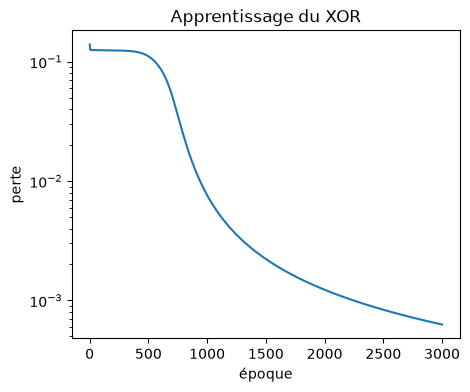

In [11]:
X_xor = np.array([[0.0, 1.0, 0.0, 1.0],
                  [0.0, 0.0, 1.0, 1.0]])
T_xor = np.array([[0.0, 1.0, 1.0, 0.0]])
acts_xor = ["sigmoide", "sigmoide"]

params = init_reseau([2, 3, 1], graine=0, echelle=1.0)
hist = entrainer(X_xor, T_xor, params, acts_xor, eta=2.0, epoques=3000)
sortie = avant(X_xor, params, acts_xor)[1][-1]
assert hist["train"][-1] < 0.01, "le réseau doit apprendre le XOR"
print("Sorties après apprentissage :", sortie.round(3), "pour les cibles", T_xor)
plt.semilogy(range(1, len(hist["train"]) + 1), hist["train"])
plt.xlabel("époque")
plt.ylabel("perte")
plt.title("Apprentissage du XOR")
plt.show()

### 4.a. Le pas d'apprentissage $\eta$

**Prédiction avant d'exécuter.** Entraînez le même réseau (même graine) avec $\eta\in\{0{,}05;\ 0{,}5;\ 2;\ 10\}$ pendant 2000 époques. Que va-t-il se passer pour la perte ?

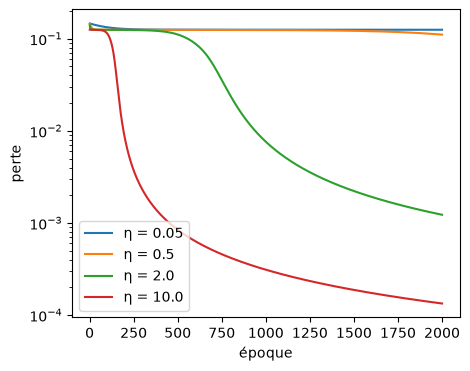

In [12]:
etas = [0.05, 0.5, 2.0, 10.0]
for eta in etas:
    params = init_reseau([2, 3, 1], graine=0, echelle=1.0)
    hist = entrainer(X_xor, T_xor, params, acts_xor, eta=eta, epoques=2000)
    plt.semilogy(range(1, len(hist["train"]) + 1), hist["train"], label=f"η = {eta}")
plt.xlabel("époque")
plt.ylabel("perte")
plt.legend()
plt.show()

**Question.** Que constatez-vous pour les petits pas ? Quelle est la valeur du « plateau » sur lequel la perte stagne, et pourquoi ?

**Réponse.** Plus le pas est petit, plus la perte reste longtemps sur un plateau proche de $0{,}125$, et plus l'apprentissage est lent : avec $\eta=0{,}05$ ou $0{,}5$ la perte stagne encore à la fin des 2000 époques, avec $\eta=2$ elle quitte le plateau vers l'époque 700, et avec $\eta=10$ en quelques centaines d'époques au plus. Ce plateau correspond à une sortie voisine de $\tfrac12$ pour les quatre points : la perte vaut alors $\tfrac12\left(\tfrac12\right)^2=0{,}125$. Au départ, le réseau est près d'un point où les gradients sont petits ; un grand pas s'en échappe vite, un petit pas met très longtemps. (Sur une fonction quadratique, comme dans l'exercice [Un pas de descente trop grand](https://openyourmath.org/exercise/Anuh) (`Anuh`), un pas trop grand fait au contraire osciller ou diverger ; ici, aucun des pas essayés ne diverge.)

### 4.b. L'initialisation

On entraîne le même réseau de trois façons : poids tirés au hasard (référence), **tous les poids nuls**, et **tous les poids égaux à 0,5**.

**Prédiction.** Que va-t-il se passer dans les deux derniers cas ?

In [13]:
def init_constante(tailles, c):
    """Réseau dont tous les poids valent c et tous les biais 0."""
    return [[np.full((n, p), c), np.zeros(n)] for p, n in zip(tailles[:-1], tailles[1:])]

In [14]:
# Test
P = init_constante([2, 3, 1], 0.5)
assert P[0][0].shape == (3, 2) and P[1][0].shape == (1, 3) and np.all(P[0][0] == 0.5) and np.all(P[1][1] == 0)

resultats = {}
for nom, depart in [("hasard", init_reseau([2, 3, 1], graine=0, echelle=1.0)),
                    ("zéro", init_constante([2, 3, 1], 0.0)),
                    ("constante 0,5", init_constante([2, 3, 1], 0.5))]:
    h = entrainer(X_xor, T_xor, depart, acts_xor, eta=2.0, epoques=3000)
    resultats[nom] = (h, depart)
    lignes_egales = all(np.allclose(depart[0][0][0], depart[0][0][j]) for j in range(1, 3))
    print(f"{nom:14}: perte finale {h['train'][-1]:.4f} | lignes de W1 identiques : {lignes_egales}")

assert resultats["hasard"][0]["train"][-1] < 0.01
assert resultats["zéro"][0]["train"][-1] > 0.1 and resultats["constante 0,5"][0]["train"][-1] > 0.05

# Pour l'initialisation nulle, les gradients sont nuls dès le départ :
P0 = init_constante([2, 3, 1], 0.0)
Z, A = avant(X_xor, P0, acts_xor)
print("Gradients au départ (poids nuls) :", [np.abs(g[0]).max() for g in arriere(Z, A, P0, acts_xor, T_xor)])

hasard        : perte finale 0.0006 | lignes de W1 identiques : False
zéro          : perte finale 0.1250 | lignes de W1 identiques : True


constante 0,5 : perte finale 0.0856 | lignes de W1 identiques : True
Gradients au départ (poids nuls) : [np.float64(0.0), np.float64(0.0)]


**Question.** Expliquez les deux échecs. Pourquoi les poids nuls ne bougent-ils pas du tout ? Pourquoi les poids constants sont-ils aussi un problème ?

**Réponse.** **Poids nuls.** Toutes les activations cachées valent $\sigma(0)=\tfrac12$ et la sortie vaut $\tfrac12$. Les deux cibles à 1 et les deux cibles à 0 donnent des termes $(a-t)$ opposés qui s'annulent dans les sommes : les gradients de la couche de sortie sont nuls. Comme $W^{[2]}=0$, la rétropropagation vers la couche cachée donne aussi zéro. Tous les gradients sont nuls : le point de départ est un point critique, rien ne bouge, la perte reste à $0{,}125$.

**Poids constants.** Les trois neurones cachés reçoivent exactement les mêmes poids, donc calculent la même chose et reçoivent exactement les mêmes mises à jour : les trois lignes de $W^{[1]}$ restent identiques à jamais (la symétrie n'est jamais brisée). Le réseau est alors équivalent à un seul neurone caché, c'est-à-dire à une séparation par une droite composée avec des fonctions croissantes : il ne peut pas apprendre le XOR (argument du milieu du segment, voir l'exercice [Pourquoi plusieurs couches ? Le problème XOR](https://openyourmath.org/exercise/KmBY) (`KmBY`)). C'est pour casser cette symétrie qu'on initialise les poids **au hasard**.

### 4.c. La ReLU morte

Reprenons l'exercice [Quand une ReLU bloque l'apprentissage](https://openyourmath.org/exercise/LT4V) (`LT4V`) : un neurone caché ReLU puis une sortie linéaire **sans biais**, une seule donnée $(x,t)=(1,2)$, deux initialisations $A=(w,b,v)=(-1,0,1)$ et $B=(1,0,1)$. Pour reproduire ce modèle, on fige le biais de sortie à 0 (on annule son gradient).

initialisation A: perte 2.000 -> 2.00000, (w, b, v) = (-1.000, 0.000, 1.000)
initialisation B: perte 0.500 -> 0.00000, (w, b, v) = (1.272, 0.272, 1.295)


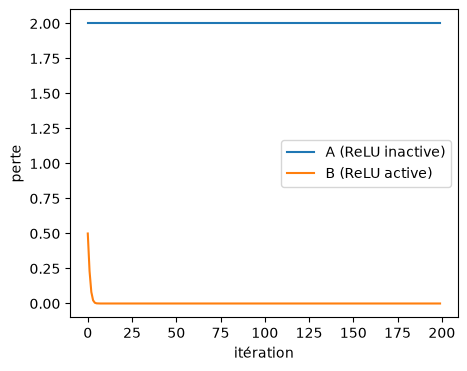

In [15]:
acts_relu = ["relu", "identite"]
X_un = np.array([[1.0]])
T_un = np.array([[2.0]])

historiques = {}
for nom, (w, b, v) in {"A": (-1.0, 0.0, 1.0), "B": (1.0, 0.0, 1.0)}.items():
    P = [[np.array([[w]]), np.array([b])], [np.array([[v]]), np.array([0.0])]]
    pertes = []
    for _ in range(200):
        Z, A = avant(X_un, P, acts_relu)
        pertes.append(perte(A[-1], T_un))
        grads = arriere(Z, A, P, acts_relu, T_un)
        grads[-1] = (grads[-1][0], np.zeros_like(grads[-1][1]))   # biais de sortie figé
        mise_a_jour(P, grads, 0.1)
    historiques[nom] = pertes
    print(f"initialisation {nom}: perte {pertes[0]:.3f} -> {pertes[-1]:.5f}, (w, b, v) = "
          f"({P[0][0][0, 0]:.3f}, {P[0][1][0]:.3f}, {P[1][0][0, 0]:.3f})")

assert np.isclose(historiques["A"][-1], 2.0), "depuis A, rien ne doit bouger"
assert historiques["B"][-1] < 1e-3, "depuis B, la perte doit tomber à presque 0"
plt.plot(historiques["A"], label="A (ReLU inactive)")
plt.plot(historiques["B"], label="B (ReLU active)")
plt.xlabel("itération")
plt.ylabel("perte")
plt.legend()
plt.show()

**Question.** Pourquoi la perte reste-t-elle bloquée à 2 depuis $A$, alors qu'elle n'est pas nulle ? Que se passerait-il avec plusieurs données ?

**Réponse.** Depuis $A$, la préactivation vaut $w x+b=-1<0$ : la ReLU est inactive, sa sortie et sa dérivée valent 0. Le gradient par rapport à $v$ contient la sortie $h=0$, et ceux par rapport à $w$ et $b$ contiennent la dérivée de la ReLU, qui vaut 0 : les trois composantes du gradient sont nulles, donc les paramètres ne changent pas, bien que la perte soit $2$. Avec plusieurs données, un neurone qui reste inactif sur **toutes** les données ne reçoit jamais de gradient et reste « mort » ; si au moins une donnée l'active, il peut encore apprendre.

## 5. Méthodes d'apprentissage

On passe à un problème où il faut vraiment *généraliser* : séparer deux « lunes » de points bruités. `deux_lunes` (fournie) fabrique le jeu de données ; la fonction `tracer_frontiere` colorie le plan selon la sortie du réseau.

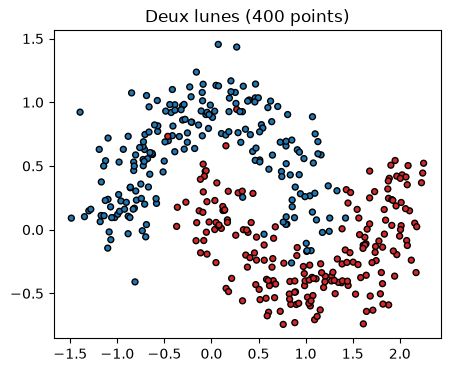

In [16]:
def deux_lunes(m=400, bruit=0.2, graine=0):
    rng = np.random.default_rng(graine)
    m1 = m // 2
    m0 = m - m1
    a1 = rng.uniform(0, np.pi, m1)
    a0 = rng.uniform(0, np.pi, m0)
    X1 = np.vstack([np.cos(a1), np.sin(a1)])
    X0 = np.vstack([1 - np.cos(a0), 0.5 - np.sin(a0)])
    X = np.hstack([X1, X0]) + rng.normal(0, bruit, (2, m))
    T = np.concatenate([np.ones(m1), np.zeros(m0)])[None, :]
    p = rng.permutation(m)
    return X[:, p], T[:, p]


def precision(sortie, T):
    """Proportion d'exemples bien classés (sortie >= 1/2 <=> classe 1)."""
    return float(np.mean((sortie >= 0.5) == (T >= 0.5)))


def tracer_frontiere(params, acts, X, T, ax=None, titre="", xlim=(-1.8, 2.8), ylim=(-1.4, 1.9)):
    ax = ax if ax is not None else plt.gca()
    xs = np.linspace(*xlim, 200)
    ys = np.linspace(*ylim, 200)
    XX, YY = np.meshgrid(xs, ys)
    G = np.vstack([XX.ravel(), YY.ravel()])
    Z = avant(G, params, acts)[1][-1].reshape(XX.shape)
    ax.contourf(XX, YY, Z, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.45)
    ax.scatter(X[0], X[1], c=np.where(T[0] >= 0.5, "tab:blue", "tab:red"), edgecolor="k", s=18, zorder=3)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(titre)


X_lunes, T_lunes = deux_lunes(400, 0.2, graine=0)
X_test, T_test = deux_lunes(400, 0.2, graine=1)
plt.scatter(X_lunes[0], X_lunes[1], c=np.where(T_lunes[0] >= 0.5, "tab:blue", "tab:red"), edgecolor="k", s=18)
plt.title("Deux lunes (400 points)")
plt.show()

### 5.a. Lot complet, mini-lots, un exemple à la fois

On entraîne le même réseau `[2, 16, 1]` (ReLU puis sigmoïde) pendant 300 époques de trois façons :
- **lot complet** (`taille_lot=None`), $\eta=0{,}5$ ;
- **mini-lots de 32** exemples, $\eta=0{,}5$ ;
- **un exemple à la fois** (`taille_lot=1`, descente stochastique), $\eta=0{,}05$ (un pas plus petit, car chaque pas est bruité).

**Prédiction.** Combien de mises à jour de paramètres chaque méthode fait-elle par époque (400 exemples) ? Qu'en attendez-vous pour la perte après un même nombre d'époques ? Et pour le temps de calcul ?

lot complet     : perte 0.0363 (test 0.0348), précision test 0.910, durée 0.0 s


mini-lots de 32 : perte 0.0130 (test 0.0167), précision test 0.945, durée 0.2 s


un exemple      : perte 0.0105 (test 0.0158), précision test 0.953, durée 2.4 s


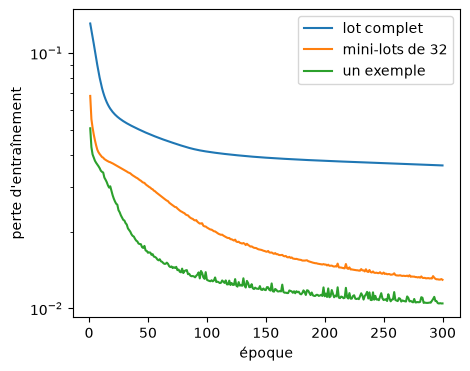

In [17]:
configurations = [("lot complet", None, 0.5), ("mini-lots de 32", 32, 0.5), ("un exemple", 1, 0.05)]
acts_lunes = ["relu", "sigmoide"]
historiques = {}
for nom, taille_lot, eta in configurations:
    params = init_reseau([2, 16, 1], graine=0, echelle=0.8)
    debut = time.time()
    hist = entrainer(X_lunes, T_lunes, params, acts_lunes, eta=eta, epoques=300,
                     taille_lot=taille_lot, X_val=X_test, T_val=T_test)
    duree = time.time() - debut
    historiques[nom] = hist
    sortie = avant(X_test, params, acts_lunes)[1][-1]
    print(f"{nom:16}: perte {hist['train'][-1]:.4f} (test {hist['val'][-1]:.4f}), "
          f"précision test {precision(sortie, T_test):.3f}, durée {duree:.1f} s")
for nom, hist in historiques.items():
    plt.semilogy(range(1, len(hist["train"]) + 1), hist["train"], label=nom)
plt.xlabel("époque")
plt.ylabel("perte d'entraînement")
plt.legend()
plt.show()

**Question.** Comparez les trois méthodes : nombre de mises à jour par époque, vitesse de décroissance de la perte, bruit des courbes, coût de calcul.

**Réponse.** Pour 400 exemples, le lot complet fait **1** mise à jour par époque, les mini-lots de 32 en font **13** (le dernier lot n'a que 16 exemples) et la méthode à un exemple en fait **400**. À nombre d'époques égal, plus on met à jour souvent, plus la perte baisse vite : le lot complet est le plus lent, les deux autres sont nettement meilleurs, avec ici la meilleure précision de test pour la méthode à un exemple. En contrepartie, la courbe du lot complet est parfaitement régulière alors que celles des deux autres sont bruitées (le gradient d'un petit lot est une estimation du gradient complet), et le temps de calcul par époque augmente fortement quand le lot est petit (400 petits calculs au lieu d'un gros). Les mini-lots sont le compromis usuel : peu bruités, vite, et efficaces avec des calculs matriciels.

### 5.b. Généraliser : entraînement et validation

Un bon réseau n'est pas celui qui s'ajuste le mieux aux points d'entraînement, mais celui qui classe bien des points **qu'il n'a jamais vus**. On construit un petit jeu d'entraînement de **30 points** très bruités, un jeu de validation de 600 points, et un grand réseau `[2, 64, 64, 1]` entraîné en lot complet pendant 2000 époques.

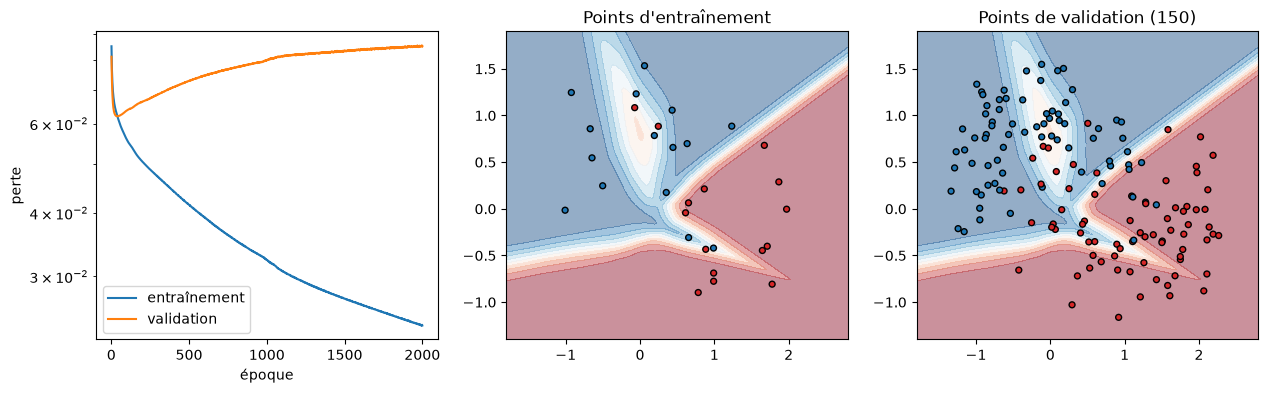

précision entraînement : 0.9666666666666667
précision validation   : 0.7566666666666667


In [18]:
X_ent, T_ent = deux_lunes(30, 0.35, graine=3)
X_val, T_val = deux_lunes(600, 0.35, graine=4)
acts_gros = ["relu", "relu", "sigmoide"]

params = init_reseau([2, 64, 64, 1], graine=0, echelle=0.3)
hist = entrainer(X_ent, T_ent, params, acts_gros, eta=0.3, epoques=2000, X_val=X_val, T_val=T_val)
params_fin = [[W.copy(), b.copy()] for W, b in params]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].semilogy(range(1, len(hist["train"]) + 1), hist["train"], label="entraînement")
axes[0].semilogy(range(1, len(hist["val"]) + 1), hist["val"], label="validation")
axes[0].set_xlabel("époque")
axes[0].set_ylabel("perte")
axes[0].legend()
tracer_frontiere(params, acts_gros, X_ent, T_ent, ax=axes[1], titre="Points d'entraînement")
tracer_frontiere(params, acts_gros, X_val[:, :150], T_val[:, :150], ax=axes[2], titre="Points de validation (150)")
plt.show()
print("précision entraînement :", precision(avant(X_ent, params, acts_gros)[1][-1], T_ent))
print("précision validation   :", precision(avant(X_val, params, acts_gros)[1][-1], T_val))

**Arrêt précoce.** Repérez l'époque où la perte de validation est minimale, puis ré-entraînez le réseau **depuis le même départ** en vous arrêtant à cette époque (la graine est la même, la trajectoire est donc identique jusque-là). Les époques sont comptées à partir de 1 : `hist["val"][0]` est la perte après une époque, donc un minimum à l'indice `indice_min` correspond à `indice_min + 1` époques effectuées.

In [19]:
indice_min = int(np.argmin(hist["val"]))
nb_epoques = indice_min + 1
print("perte de validation minimale après", nb_epoques, "époques")

params_arret = init_reseau([2, 64, 64, 1], graine=0, echelle=0.3)
hist_arret = entrainer(X_ent, T_ent, params_arret, acts_gros, eta=0.3, epoques=nb_epoques,
                       X_val=X_val, T_val=T_val)

perte de validation minimale après 37 époques


In [20]:
# Test
assert indice_min is not None and nb_epoques is not None, "calculez indice_min et nb_epoques"
assert nb_epoques == indice_min + 1, "l'indice 0 correspond à une époque effectuée"
assert hist["val"][-1] > 1.2 * min(hist["val"]), "la perte de validation doit remonter nettement après son minimum"
perte_val_arret = perte(avant(X_val, params_arret, acts_gros)[1][-1], T_val)
perte_val_fin = perte(avant(X_val, params_fin, acts_gros)[1][-1], T_val)
assert np.isclose(perte_val_arret, min(hist["val"])), "l'arrêt précoce doit retrouver la perte de validation minimale"
print(f"perte de validation : arrêt après {nb_epoques} époques -> {perte_val_arret:.4f} ; après 2000 époques -> {perte_val_fin:.4f}")
print("précision de validation :",
      f"arrêt précoce {precision(avant(X_val, params_arret, acts_gros)[1][-1], T_val):.3f}",
      f"| fin {precision(avant(X_val, params_fin, acts_gros)[1][-1], T_val):.3f}")

perte de validation : arrêt après 37 époques -> 0.0620 ; après 2000 époques -> 0.0852
précision de validation : arrêt précoce 0.825 | fin 0.757


**Question.** Que montrent les deux courbes ? À quelle époque faut-il s'arrêter, et pourquoi la perte d'entraînement n'est-elle pas un bon critère ?

**Réponse.** La perte d'entraînement baisse globalement, avec de petites fluctuations, jusqu'à devenir très faible (le réseau classe presque tous les 30 points d'entraînement, la frontière se tord pour en contourner certains), alors que la perte de validation passe par un minimum très tôt (après 37 époques) puis **remonte** : le réseau, trop flexible pour 30 points bruités, se met à apprendre le bruit — c'est le **sur-apprentissage**. La précision sur des points inconnus (environ 76 % à la fin) est bien inférieure à celle sur les points d'entraînement (97 %). Il faut s'arrêter à l'époque de la perte de validation minimale (**arrêt précoce**) : ici la perte de validation passe de $0{,}085$ à $0{,}062$ et la précision de validation de $76\,\%$ à $82\,\%$. La perte d'entraînement ne convient pas comme critère : elle ne mesure pas la capacité à généraliser. Sa diminution n'est pas garantie à chaque mise à jour : elle dépend du pas choisi et de la méthode d'apprentissage.

### 5.c. Pénaliser les poids (régularisation $L^2$)

Dans l'exercice [Ajuster une droite en pénalisant sa pente](https://openyourmath.org/exercise/wkRy) (`wkRy`), on minimisait $J_\lambda=\text{erreur}+\lambda a^2$ et la pénalisation réduisait la pente de 1 à $\tfrac13$. On fait de même ici : on minimise $E+\lambda\sum_\ell\|W^{[\ell]}\|^2$ (les biais ne sont pas pénalisés). La dérivée de $\lambda\|W\|^2$ est $2\lambda W$ : à chaque mise à jour, le gradient de chaque matrice de poids reçoit le terme $2\lambda W^{[\ell]}$. On parle de *weight decay*, car les poids sont « tirés vers zéro » à chaque pas.

Écrivez `ajouter_decroissance(grads, params, lam)`, utilisée par `entrainer` quand `lam > 0`.

In [21]:
def ajouter_decroissance(grads, params, lam):
    """Ajoute 2*lam*W au gradient de chaque matrice de poids W (pas aux biais)."""
    return [(dW + 2 * lam * W, db) for (dW, db), (W, b) in zip(grads, params)]

lambda = 0.0   : perte entraînement 0.0240 | perte validation 0.0852 | précision validation 0.757


lambda = 0.001 : perte entraînement 0.0487 | perte validation 0.0738 | précision validation 0.800


lambda = 0.003 : perte entraînement 0.0664 | perte validation 0.0680 | précision validation 0.813


lambda = 0.01  : perte entraînement 0.0767 | perte validation 0.0739 | précision validation 0.798


lambda = 0.03  : perte entraînement 0.1250 | perte validation 0.1250 | précision validation 0.500


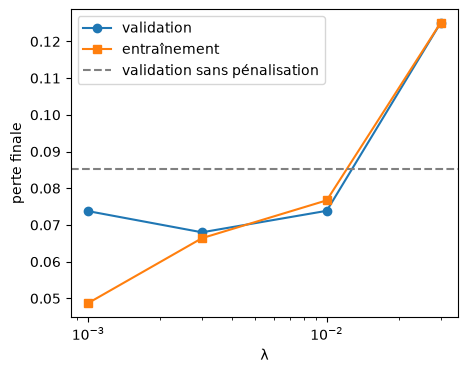

In [22]:
# Test
g = ajouter_decroissance([(np.zeros((2, 2)), np.zeros(2))], [[np.ones((2, 2)), np.ones(2)]], 0.1)
assert np.allclose(g[0][0], 0.2) and np.allclose(g[0][1], 0), "dW + 2 lam W pour les poids, db inchangé"

valeurs = [0.0, 1e-3, 3e-3, 1e-2, 3e-2]
perte_val, prec_val, perte_ent = [], [], []
for lam in valeurs:
    P = init_reseau([2, 64, 64, 1], graine=0, echelle=0.3)
    h = entrainer(X_ent, T_ent, P, acts_gros, eta=0.3, epoques=2000, X_val=X_val, T_val=T_val, lam=lam)
    perte_val.append(h["val"][-1])
    perte_ent.append(h["train"][-1])
    prec_val.append(precision(avant(X_val, P, acts_gros)[1][-1], T_val))
    print(f"lambda = {lam:<6}: perte entraînement {perte_ent[-1]:.4f} | perte validation {perte_val[-1]:.4f} | "
          f"précision validation {prec_val[-1]:.3f}")
assert perte_val[2] < perte_val[0], "une pénalisation modérée doit améliorer la perte de validation"

plt.semilogx(valeurs[1:], perte_val[1:], "o-", label="validation")
plt.semilogx(valeurs[1:], perte_ent[1:], "s-", label="entraînement")
plt.axhline(perte_val[0], color="gray", ls="--", label="validation sans pénalisation")
plt.xlabel("λ")
plt.ylabel("perte finale")
plt.legend()
plt.show()

**Question.** Comment évolue la perte de validation quand $\lambda$ augmente ? Que se passe-t-il pour $\lambda=0{,}03$ ? Faites le lien avec l'exercice [Ajuster une droite en pénalisant sa pente](https://openyourmath.org/exercise/wkRy) (`wkRy`).

**Réponse.** Pour $\lambda$ petit, la pénalisation n'a presque pas d'effet. Pour une valeur modérée ($\lambda\approx 3\cdot 10^{-3}$), la perte de validation passe de $0{,}085$ à $0{,}068$ et la précision de validation de $76\,\%$ à $81\,\%$, alors que la perte d'entraînement **augmente** : on accepte de moins bien ajuster les points d'entraînement pour mieux généraliser. Pour $\lambda=0{,}03$, la pénalisation est trop forte : les poids sont écrasés vers 0, le réseau répond $\tfrac12$ partout (perte $0{,}125$, précision $50\,\%$) : c'est du **sous-apprentissage**. Il y a donc un compromis, à choisir sur le jeu de validation. C'est le même mécanisme que dans l'exercice [Ajuster une droite en pénalisant sa pente](https://openyourmath.org/exercise/wkRy) (`wkRy`), où la pénalisation $\lambda a^2$ faisait passer la pente de $1$ à $\tfrac13$ au prix d'erreurs non nulles sur les observations : la régularisation $L^2$ contraint les paramètres à rester petits.

## 6. Pour aller plus loin : une rétropropagation automatique

Votre fonction `arriere` est écrite *pour des couches denses*. La rétropropagation est en fait la **règle de la chaîne appliquée sur un graphe de calcul**, en parcourant le graphe à l'envers. Pour le voir, on écrit une minuscule classe `Valeur` : chaque opération sur des `Valeur` mémorise comment propager un gradient vers ses opérandes.

Chaque appel à `backward` remet les gradients à zéro avant de les recalculer : les contributions de plusieurs chemins sont cumulées pendant ce seul passage.

Les méthodes `__add__` et `__pow__` sont fournies. Écrivez `__mul__` (si $s=u\,v$ alors $\partial s/\partial u=v$ et $\partial s/\partial v=u$), `relu`, et `backward`, qui parcourt le graphe dans l'ordre inverse.

In [23]:
class Valeur:
    def __init__(self, data, enfants=()):
        self.data = float(data)
        self.grad = 0.0
        self._enfants = enfants
        self._arriere = lambda: None

    def __add__(self, autre):
        autre = autre if isinstance(autre, Valeur) else Valeur(autre)
        sortie = Valeur(self.data + autre.data, (self, autre))

        def _arriere():
            self.grad += sortie.grad
            autre.grad += sortie.grad
        sortie._arriere = _arriere
        return sortie

    def __mul__(self, autre):
        autre = autre if isinstance(autre, Valeur) else Valeur(autre)
        sortie = Valeur(self.data * autre.data, (self, autre))

        def _arriere():
            self.grad += autre.data * sortie.grad
            autre.grad += self.data * sortie.grad
        sortie._arriere = _arriere
        return sortie

    def __pow__(self, p):
        sortie = Valeur(self.data ** p, (self,))

        def _arriere():
            self.grad += p * self.data ** (p - 1) * sortie.grad
        sortie._arriere = _arriere
        return sortie

    def relu(self):
        sortie = Valeur(max(0.0, self.data), (self,))

        def _arriere():
            self.grad += (1.0 if self.data > 0 else 0.0) * sortie.grad
        sortie._arriere = _arriere
        return sortie

    def backward(self):
        """Recalcule les gradients du graphe, remis à zéro à chaque appel."""
        ordre, vus = [], set()

        def parcourir(v):
            if id(v) not in vus:
                vus.add(id(v))
                for e in v._enfants:
                    parcourir(e)
                ordre.append(v)
        parcourir(self)
        for v in ordre:
            v.grad = 0.0
        self.grad = 1.0
        for v in reversed(ordre):
            v._arriere()

    __radd__ = __add__
    __rmul__ = __mul__

    def __neg__(self):
        return self * -1

    def __sub__(self, autre):
        return self + (-autre)

**Test : encore l'exercice *Une rétropropagation de bout en bout*.** On écrit le calcul tel quel, puis on appelle `backward` : on doit retrouver les gradients $(2,2,1,1)$ sans avoir écrit une seule formule de rétropropagation.

In [24]:
# Test
w1, b1, w2, b2 = Valeur(1.0), Valeur(0.0), Valeur(2.0), Valeur(0.0)
x, t = 1.0, 1.0
h = (w1 * x + b1).relu()
F = w2 * h + b2
E = 0.5 * (F - t) ** 2
E.backward()
assert np.isclose(E.data, 0.5)
assert np.allclose([w1.grad, b1.grad, w2.grad, b2.grad], [2.0, 2.0, 1.0, 1.0]), (w1.grad, b1.grad, w2.grad, b2.grad)
# Un second appel recalcule les mêmes gradients, sans cumuler les passages.
E.backward()
assert np.allclose([w1.grad, b1.grad, w2.grad, b2.grad], [2.0, 2.0, 1.0, 1.0])

# Une même valeur peut intervenir par plusieurs chemins du graphe.
u = Valeur(2.0)
carre = u * u
puissance4 = carre * carre
for _ in range(2):
    puissance4.backward()
    assert np.isclose(u.grad, 32.0), "la dérivée de u⁴ en 2 vaut 32 à chaque appel"
print("Rétropropagation automatique : gradients", (w1.grad, b1.grad, w2.grad, b2.grad))

Rétropropagation automatique : gradients (2.0, 2.0, 1.0, 1.0)


**Question.** Pourquoi retrouve-t-on les mêmes gradients que par la rétropropagation écrite à la main ?

**Réponse.** Parce que c'est exactement le même calcul. Chaque opération applique sa **règle locale** (somme : le gradient passe tel quel ; produit : on multiplie par l'autre facteur ; ReLU : on laisse passer ou on bloque), et `backward` parcourt le graphe de la sortie vers les entrées en cumulant les contributions avec la règle de la chaîne. C'est ce que font PyTorch ou TensorFlow à grande échelle : on écrit seulement la propagation avant, et la rétropropagation est déduite automatiquement du graphe. Il reste indispensable de savoir ce qu'elle calcule, notamment pour comprendre les échecs vus plus haut (gradient nul, ReLU morte, symétrie).

## Fiche de résultats

Cette cellule recalcule les valeurs demandées dans l'exercice [TP Python : rétropropagation et méthodes d'apprentissage](https://openyourmath.org/exercise/bNCl) (`bNCl`) (questions 1, 2, 4, 5, 7 et 8). Elle ne fonctionne que si **toutes** les cellules précédentes sont complétées et correctes, et elle prend une quinzaine de secondes. Recopiez ce qu'elle affiche : toutes les graines sont fixées, vos résultats doivent correspondre aux arrondis demandés. L'écart calculé par différences finies peut varier selon l'environnement numérique : on vérifie qu'il reste inférieur au seuil du test, sans exiger une valeur exacte.

In [25]:
# Fiche de résultats
RESULTATS = {}

# Q1 : vérification des gradients
rng_f = np.random.default_rng(1)
P_f = init_reseau([3, 4, 2], graine=2, echelle=1.0)
X_f = rng_f.normal(size=(3, 6))
T_f = rng_f.uniform(size=(2, 6))
ecart = verifier_gradient(P_f, ["sigmoide", "sigmoide"], X_f, T_f)
RESULTATS["q1"] = float(ecart)
print(f"Q1. Écart relatif maximal (réseau [3, 4, 2] sigmoïde) : {ecart:.1e}")

# Q2 : le XOR
P_f = init_reseau([2, 3, 1], graine=0, echelle=1.0)
h_f = entrainer(X_xor, T_xor, P_f, acts_xor, eta=2.0, epoques=3000)
sorties = np.round(avant(X_xor, P_f, acts_xor)[1][-1][0], 2)
RESULTATS["q2"] = {"perte": float(h_f["train"][-1]), "sorties": [float(v) for v in sorties]}
print(f"Q2. XOR [2, 3, 1], eta = 2, 3000 époques : perte finale {h_f['train'][-1]:.4f}, sorties {sorties}")

# Q4 : la ReLU morte (biais de sortie figé)
def relu_morte(w, b, v, iterations=200, eta=0.1):
    P = [[np.array([[w]]), np.array([b])], [np.array([[v]]), np.array([0.0])]]
    for _ in range(iterations):
        Z, A = avant(np.array([[1.0]]), P, ["relu", "identite"])
        g = arriere(Z, A, P, ["relu", "identite"], np.array([[2.0]]))
        g[-1] = (g[-1][0], np.zeros_like(g[-1][1]))
        mise_a_jour(P, g, eta)
    return P, perte(avant(np.array([[1.0]]), P, ["relu", "identite"])[1][-1], np.array([[2.0]]))


P_A, perte_A = relu_morte(-1.0, 0.0, 1.0)
P_B, perte_B = relu_morte(1.0, 0.0, 1.0)
RESULTATS["q4"] = {"perte_A": float(perte_A), "perte_B": float(perte_B), "w_B": float(P_B[0][0][0, 0])}
print(f"Q4. ReLU morte, après 200 itérations : perte {perte_A:.3f} depuis A, {perte_B:.3f} depuis B ; w = {P_B[0][0][0, 0]:.2f} depuis B")

# Q5 : lot complet, mini-lots, un exemple à la fois
RESULTATS["q5"] = {}
for nom, taille_lot, eta in [("lot complet", None, 0.5), ("mini-lots de 32", 32, 0.5), ("un exemple", 1, 0.05)]:
    P = init_reseau([2, 16, 1], graine=0, echelle=0.8)
    h = entrainer(X_lunes, T_lunes, P, acts_lunes, eta=eta, epoques=300, taille_lot=taille_lot)
    pr = precision(avant(X_test, P, acts_lunes)[1][-1], T_test)
    RESULTATS["q5"][nom] = {"perte": float(h["train"][-1]), "precision": float(pr)}
    print(f"Q5. {nom:16}: perte d'entraînement {h['train'][-1]:.4f}, précision de test {pr:.3f}")

# Q7 : arrêt précoce
P_gros = init_reseau([2, 64, 64, 1], graine=0, echelle=0.3)
h_gros = entrainer(X_ent, T_ent, P_gros, acts_gros, eta=0.3, epoques=2000, X_val=X_val, T_val=T_val)
nb_epoques_min = int(np.argmin(h_gros["val"])) + 1
P_es = init_reseau([2, 64, 64, 1], graine=0, echelle=0.3)
entrainer(X_ent, T_ent, P_es, acts_gros, eta=0.3, epoques=nb_epoques_min)
prec_fin = precision(avant(X_val, P_gros, acts_gros)[1][-1], T_val)
prec_es = precision(avant(X_val, P_es, acts_gros)[1][-1], T_val)
RESULTATS["q7"] = {"epoque": nb_epoques_min, "val_min": float(min(h_gros["val"])), "val_fin": float(h_gros["val"][-1]),
                   "precision_arret": float(prec_es), "precision_fin": float(prec_fin)}
print(f"Q7. Perte de validation minimale après {nb_epoques_min} époques ({min(h_gros['val']):.4f}) contre {h_gros['val'][-1]:.4f} à la fin ; "
      f"précision de validation {prec_es:.3f} (arrêt précoce) contre {prec_fin:.3f} (fin)")

# Q8 : pénalisation L2
RESULTATS["q8"] = {}
for lam in [0.0, 1e-3, 3e-3, 1e-2, 3e-2]:
    P = init_reseau([2, 64, 64, 1], graine=0, echelle=0.3)
    h = entrainer(X_ent, T_ent, P, acts_gros, eta=0.3, epoques=2000, X_val=X_val, T_val=T_val, lam=lam)
    pr = precision(avant(X_val, P, acts_gros)[1][-1], T_val)
    RESULTATS["q8"][str(lam)] = {"perte_val": float(h["val"][-1]), "precision": float(pr)}
    print(f"Q8. lambda = {lam:<6}: perte de validation {h['val'][-1]:.4f}, précision de validation {pr:.3f}")

Q1. Écart relatif maximal (réseau [3, 4, 2] sigmoïde) : 2.5e-08


Q2. XOR [2, 3, 1], eta = 2, 3000 époques : perte finale 0.0006, sorties [0.02 0.96 0.96 0.05]
Q4. ReLU morte, après 200 itérations : perte 2.000 depuis A, 0.000 depuis B ; w = 1.27 depuis B


Q5. lot complet     : perte d'entraînement 0.0363, précision de test 0.910


Q5. mini-lots de 32 : perte d'entraînement 0.0130, précision de test 0.945


Q5. un exemple      : perte d'entraînement 0.0105, précision de test 0.953


...

Q8. lambda = 0.0   : perte de validation 0.0852, précision de validation 0.757


Q8. lambda = 0.001 : perte de validation 0.0738, précision de validation 0.800


Q8. lambda = 0.003 : perte de validation 0.0680, précision de validation 0.813


Q8. lambda = 0.01  : perte de validation 0.0739, précision de validation 0.798


Q8. lambda = 0.03  : perte de validation 0.1250, précision de validation 0.500


### Réponses aux questions d'expérimentation de l'exercice associé

In [26]:
# Question 3 : réseau [2, 2, 1], eta = 2, 3000 époques, graines 0 à 5
pertes_22 = []
for graine in range(6):
    P = init_reseau([2, 2, 1], graine=graine, echelle=1.0)
    pertes_22.append(entrainer(X_xor, T_xor, P, acts_xor, eta=2.0, epoques=3000)["train"][-1])
bloquees = [g for g, p in enumerate(pertes_22) if p > 0.05]
RESULTATS["q3"] = {"pertes": [float(p) for p in pertes_22], "bloquees": bloquees}
print("Q3. [2, 2, 1] : pertes finales :", np.round(pertes_22, 3), "| graines bloquées (perte > 0,05) :", bloquees)
pertes_23 = []
for graine in range(6):
    P = init_reseau([2, 3, 1], graine=graine, echelle=1.0)
    pertes_23.append(entrainer(X_xor, T_xor, P, acts_xor, eta=2.0, epoques=3000)["train"][-1])
RESULTATS["q3"]["pertes_3_neurones"] = [float(p) for p in pertes_23]
print("Q3. [2, 3, 1] : pertes finales :", np.round(pertes_23, 3), "| graines bloquées :", [g for g, p in enumerate(pertes_23) if p > 0.05])

# Question 6 : mini-lots de 8
P = init_reseau([2, 16, 1], graine=0, echelle=0.8)
h8 = entrainer(X_lunes, T_lunes, P, acts_lunes, eta=0.5, epoques=300, taille_lot=8)
prec8 = precision(avant(X_test, P, acts_lunes)[1][-1], T_test)
maj = int(np.ceil(X_lunes.shape[1] / 8))
RESULTATS["q6"] = {"mises_a_jour": maj, "perte": float(h8["train"][-1]), "precision": float(prec8)}
print(f"Q6. mini-lots de 8 : {maj} mises à jour par époque, perte finale {h8['train'][-1]:.4f}, précision de test {prec8:.3f}")

import json
print("RESULTATS =", json.dumps(RESULTATS))

Q3. [2, 2, 1] : pertes finales : [0.001 0.063 0.001 0.001 0.084 0.001] | graines bloquées (perte > 0,05) : [1, 4]


Q3. [2, 3, 1] : pertes finales : [0.001 0.001 0.001 0.001 0.001 0.001] | graines bloquées : []


Q6. mini-lots de 8 : 50 mises à jour par époque, perte finale 0.0101, précision de test 0.955
RESULTATS = {"q1": 2.485663380904981e-08, "q2": {"perte": 0.0006278961168589587, "sorties": [0.02, 0.96, 0.96, 0.05]}, "q4": {"perte_A": 2.0, "perte_B": 0.0, "w_B": 1.272352583360509}, "q5": {"lot complet": {"perte": 0.036304238770460955, "precision": 0.91}, "mini-lots de 32": {"perte": 0.012950213936824224, "precision": 0.945}, "un exemple": {"perte": 0.010466688694733195, "precision": 0.9525}}, "q7": {"epoque": 37, "val_min": 0.06202989275265883, "val_fin": 0.08516910438190423, "precision_arret": 0.825, "precision_fin": 0.7566666666666667}, "q8": {"0.0": {"perte_val": 0.08516910438190423, "precision": 0.7566666666666667}, "0.001": {"perte_val": 0.07376044868076935, "precision": 0.8}, "0.003": {"perte_val": 0.06799733587050484, "precision": 0.8133333333333334}, "0.01": {"perte_val": 0.07385425300234554, "precision": 0.7983333333333333}, "0.03": {"perte_val": 0.125, "precision": 0.5}}, "q3": {

## Bilan

Vous avez programmé de bout en bout un réseau de neurones : propagation avant, perte, **rétropropagation** (vérifiée sur un exemple calculé à la main et par différences finies), mise à jour, puis les principales méthodes d'apprentissage : taille de lot, pas, initialisation, validation, arrêt précoce, pénalisation. Chaque outil se justifie par un problème concret observé : plateau, symétrie, neurone mort, sur-apprentissage.